The KNN walkthrough ended on a problem: in high dimensions every point is roughly the
same distance from every other, and distance-based methods stop working. PCA is the
standard answer &mdash; find a smaller set of directions that keeps most of the information.

The idea can be stated two ways, and they turn out to be **the same optimisation**:

* **Maximise variance.** Find the direction along which the data is most spread out, then
  the best direction orthogonal to that, and so on.
* **Minimise reconstruction error.** Find the $k$-dimensional subspace whose orthogonal
  projection loses the least squared distance.

Both lead to the eigenvectors of the covariance matrix:

$$\Sigma = \frac{1}{n-1}X_c^\top X_c, \qquad \Sigma\mathbf{v} = \lambda\mathbf{v}$$

The eigenvector with the largest $\lambda$ is the first principal component, and $\lambda$
*is* the variance along it. Everything below computes $\Sigma$, its eigenvectors and the
projection by hand, shows the SVD route to the same answer, and checks against
scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The 12 EEG recordings and their three features. These features are strongly correlated &mdash;
a recording with a high spike rate also tends to have a high line length &mdash; which is
exactly the redundancy PCA exists to remove.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [3]:
print("correlation between the raw features\n")
corr = np.corrcoef(X.T)
show_matrix(corr, "correlation", rows=feature_names, cols=feature_names,
            fmt="{:+8.4f}")
print(f"\nEvery pair is correlated above {corr[np.triu_indices(3,1)].min():.2f}.")
print("Three columns, but far less than three dimensions worth of information -")
print("that gap is what PCA measures and removes.")

correlation between the raw features

correlation (3, 3) =
             line_lengthspike_rate       age
   line_length |  +1.0000   +0.8509   +0.8806
   spike_rate |  +0.8509   +1.0000   +0.9085
          age |  +0.8806   +0.9085   +1.0000

Every pair is correlated above 0.85.
Three columns, but far less than three dimensions worth of information -
that gap is what PCA measures and removes.


---
# 2. Centring (and Scaling)

PCA measures **variance about the mean**, so the data must be centred first. Without it
the first component points at the mean itself rather than at the direction of spread.

Whether to *scale* as well is a modelling choice, not a technicality:

* **Covariance PCA** (centre only) &mdash; a feature measured in larger numbers gets more
  say. Appropriate when the units are genuinely comparable.
* **Correlation PCA** (centre and standardise) &mdash; every feature contributes equally.

Here `age` runs to 63 while `spike_rate` runs to 8, so unstandardised PCA would be almost
entirely about `age`. Both are computed below so the difference is visible.

In [4]:
mu = X.mean(axis=0)
sd = X.std(axis=0, ddof=1)
Xc = X - mu                      # centred only
Xz = Xc / sd                     # centred and scaled

print(f"feature means : {np.round(mu, 4)}")
print(f"feature stds  : {np.round(sd, 4)}\n")
show_matrix(Xc, "X centred", rows=rec_ids, cols=feature_names)
print(f"\ncolumn means after centring: {np.round(Xc.mean(axis=0), 12)}")
print(f"all zero? {np.allclose(Xc.mean(axis=0), 0)}\n")

print(f"{'feature':>12}  {'variance (raw)':>15}  {'share of total':>15}")
print("-" * 46)
v = Xc.var(axis=0, ddof=1)
for j, f in enumerate(feature_names):
    print(f"{f:>12}  {v[j]:>15.4f}  {v[j]/v.sum():>14.1%}")
print("-" * 46)
print(f"\n'{feature_names[np.argmax(v)]}' alone accounts for {v.max()/v.sum():.1%} of the raw")
print("variance - purely because of its units. That is what standardising fixes.")

feature means : [33.75    3.7833 40.6667]
feature stds  : [16.2656  2.9167 15.0414]

X centred (12, 3) =
             line_lengthspike_rate       age
        rec00 |  -21.750    -3.283   -16.667
        rec01 |  -18.750    -2.583    -9.667
        rec02 |   +8.250    +3.017   +17.333
        rec03 |   +4.250    +1.317    +6.333
        rec04 |  -22.750    -3.483   -21.667
        rec05 |  +21.250    +4.417   +22.333
        rec06 |   +6.250    -1.883    -5.667
        rec07 |  +13.250    +3.617   +11.333
        rec08 |  -19.750    -2.983   -12.667
        rec09 |  +17.250    +2.317   +19.333
        rec10 |  +11.250    -1.383    +0.333
        rec11 |   +1.250    +0.917   -10.667

column means after centring: [0. 0. 0.]
all zero? True

     feature   variance (raw)   share of total
----------------------------------------------
 line_length         264.5682           53.0%
  spike_rate           8.5070            1.7%
         age         226.2424           45.3%
---------------------

---
# 3. The Covariance Matrix

$$\Sigma_{jk} = \frac{1}{n-1}\sum_{i=1}^{n}(x_{ij}-\bar{x}_j)(x_{ik}-\bar{x}_k)
\qquad\Longleftrightarrow\qquad
\Sigma = \frac{1}{n-1}X_c^\top X_c$$

The diagonal holds the variances, the off-diagonal the covariances. It is symmetric,
which guarantees real eigenvalues and orthogonal eigenvectors &mdash; the property the whole
method rests on.

In [5]:
Sig = Xc.T @ Xc / (n_samples - 1)

show_matmul(Xc.T, Xc, Xc.T @ Xc, "Xc^T", "Xc", "Xc^T Xc", i=0, j=0,
            note=f"then divide by n-1 = {n_samples-1}")

print()
show_matrix(Sig, "Sigma = Xc^T Xc / (n-1)", rows=feature_names,
            cols=feature_names, fmt="{:+11.4f}")

print(f"\nby hand, Sigma[0,1] (covariance of {feature_names[0]} and {feature_names[1]}):")
prod = Xc[:, 0] * Xc[:, 1]
print(f"   sum of products = {' + '.join(f'({v:+.2f})' for v in prod[:5])} + ...")
print(f"                   = {prod.sum():.6f}")
print(f"   / (n-1)         = {prod.sum():.6f} / {n_samples-1} = {prod.sum()/(n_samples-1):.6f}")
print(f"   from the matrix : {Sig[0,1]:.6f}   MATCH: {np.isclose(prod.sum()/(n_samples-1), Sig[0,1])}")

print(f"\nsymmetric? {np.allclose(Sig, Sig.T)}")
print(f"diagonal = per-feature variances? "
      f"{np.allclose(np.diag(Sig), Xc.var(axis=0, ddof=1))}")
print(f"trace (total variance) = {np.trace(Sig):.6f}")
print(f"matches np.cov? {np.allclose(Sig, np.cov(X.T))}")

  Xc^T (3, 12)   @   Xc (12, 3)   =   Xc^T Xc (3, 3)
  shape rule: (3 x 12) @ (12 x 3) -> (3 x 3)   inner dim 12 cancels
  then divide by n-1 = 11

Xc^T (3, 12) =
            0 |  -21.750   -18.750    +8.250    +4.250   -22.750   +21.250    +6.250   +13.250   -19.750   +17.250   +11.250    +1.250
            1 |   -3.283    -2.583    +3.017    +1.317    -3.483    +4.417    -1.883    +3.617    -2.983    +2.317    -1.383    +0.917
            2 |  -16.667    -9.667   +17.333    +6.333   -21.667   +22.333    -5.667   +11.333   -12.667   +19.333    +0.333   -10.667

Xc (12, 3) =
            0 |  -21.750    -3.283   -16.667
            1 |  -18.750    -2.583    -9.667
            2 |   +8.250    +3.017   +17.333
            3 |   +4.250    +1.317    +6.333
            4 |  -22.750    -3.483   -21.667
            5 |  +21.250    +4.417   +22.333
            6 |   +6.250    -1.883    -5.667
            7 |  +13.250    +3.617   +11.333
            8 |  -19.750    -2.983   -12.667
            9

---
# 4. Eigendecomposition

$$\Sigma\mathbf{v} = \lambda\mathbf{v}$$

For each eigenvector $\mathbf{v}$, the variance of the data projected onto it is exactly
$\lambda$:

$$\operatorname{Var}(X_c\mathbf{v}) = \mathbf{v}^\top\Sigma\mathbf{v} = \mathbf{v}^\top\lambda\mathbf{v} = \lambda$$

That identity is why "largest eigenvalue" and "direction of greatest variance" are the
same thing &mdash; and it is verified numerically below.

In [6]:
eigval, eigvec = np.linalg.eigh(Sig)          # eigh: symmetric, returns ascending
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]

print("eigenvalues, largest first\n")
print(f"{'PC':>4}  {'eigenvalue':>13}  {'variance share':>15}  {'cumulative':>12}")
print("-" * 50)
cum = 0
for k in range(n_features):
    cum += eigval[k] / eigval.sum()
    print(f"PC{k+1:>2}  {eigval[k]:>13.6f}  {eigval[k]/eigval.sum():>14.2%}  {cum:>11.2%}")
print("-" * 50)
print(f"sum of eigenvalues = {eigval.sum():.6f}")
print(f"trace of Sigma     = {np.trace(Sig):.6f}")
print(f"MATCH: {np.isclose(eigval.sum(), np.trace(Sig))}")
print("\n(that equality is not a coincidence - PCA redistributes the same total")
print(" variance across new axes, it does not create or destroy any)\n")

print("eigenvectors (the principal directions)\n")
show_matrix(eigvec.T, "components (rows = PC1, PC2, PC3)",
            rows=[f"PC{k+1}" for k in range(n_features)],
            cols=feature_names, fmt="{:+10.6f}")

print(f"\nverifying Sigma v = lambda v for PC1:\n")
v1 = eigvec[:, 0]
lhs, rhs = Sig @ v1, eigval[0] * v1
print(f"   Sigma @ v1  = {np.round(lhs, 8)}")
print(f"   lambda * v1 = {np.round(rhs, 8)}")
print(f"   MATCH: {np.allclose(lhs, rhs)}")

print(f"\northonormality:")
print(f"   ||v1|| = {np.linalg.norm(v1):.10f}")
print(f"   v1.v2  = {v1 @ eigvec[:,1]:+.3e}")
print(f"   V^T V = I ? {np.allclose(eigvec.T @ eigvec, np.eye(n_features))}")

eigenvalues, largest first

  PC     eigenvalue   variance share    cumulative
--------------------------------------------------
PC 1     468.693715          93.87%       93.87%
PC 2      29.264932           5.86%       99.73%
PC 3       1.358929           0.27%      100.00%
--------------------------------------------------
sum of eigenvalues = 499.317576
trace of Sigma     = 499.317576
MATCH: True

(that equality is not a coincidence - PCA redistributes the same total
 variance across new axes, it does not create or destroy any)

eigenvectors (the principal directions)

components (rows = PC1, PC2, PC3) (3, 3) =
             line_lengthspike_rate       age
          PC1 |  -0.731824   -0.122264   -0.670436
          PC2 |  -0.680432   +0.076208   +0.728838
          PC3 |  +0.038018   -0.989567   +0.138963

verifying Sigma v = lambda v for PC1:

   Sigma @ v1  = [-343.0015  -57.3045 -314.2291]
   lambda * v1 = [-343.0015  -57.3045 -314.2291]
   MATCH: True

orthonormality:
   ||v1||

In [7]:
print("the key identity: variance along a direction = its eigenvalue\n")
scores_all = Xc @ eigvec
print(f"{'PC':>4}  {'var of projection':>19}  {'eigenvalue':>13}  {'match':>7}")
print("-" * 50)
for k in range(n_features):
    vv = scores_all[:, k].var(ddof=1)
    print(f"PC{k+1:>2}  {vv:>19.8f}  {eigval[k]:>13.8f}  "
          f"{str(np.isclose(vv, eigval[k])):>7}")
print("-" * 50)

print(f"\nand no other direction beats PC1 - testing 20000 random unit vectors:\n")
rng = np.random.default_rng(0)
R = rng.normal(size=(20000, n_features))
R /= np.linalg.norm(R, axis=1, keepdims=True)
var_r = np.einsum("ij,jk,ik->i", R, Sig, R)
print(f"   variance along PC1        : {eigval[0]:.6f}")
print(f"   best of 20000 random dirs : {var_r.max():.6f}")
print(f"   any random direction better? {var_r.max() > eigval[0] + 1e-9}")
print(f"   mean random direction     : {var_r.mean():.6f}")

the key identity: variance along a direction = its eigenvalue

  PC    var of projection     eigenvalue    match
--------------------------------------------------
PC 1         468.69371465   468.69371465     True
PC 2          29.26493224    29.26493224     True
PC 3           1.35892887     1.35892887     True
--------------------------------------------------

and no other direction beats PC1 - testing 20000 random unit vectors:

   variance along PC1        : 468.693715
   best of 20000 random dirs : 468.601415
   any random direction better? False
   mean random direction     : 167.264257


---
# 5. Projection and Reconstruction

$$\text{scores: } \; Z = X_c V_k
\qquad\qquad
\text{reconstruction: } \; \hat{X} = Z V_k^\top + \boldsymbol{\mu}$$

Keeping all components loses nothing &mdash; it is just a rotation. Keeping $k < p$ discards
the variance in the dropped directions, and that discarded variance **is** the mean
squared reconstruction error:

$$\frac{1}{n}\sum_i\lVert\mathbf{x}_i - \hat{\mathbf{x}}_i\rVert^2
\;\propto\; \sum_{j>k}\lambda_j$$

In [8]:
scores = Xc @ eigvec
print("scores: each recording expressed in the new coordinate system\n")
show_matrix(scores, "Z = Xc V", rows=rec_ids,
            cols=[f"PC{k+1}" for k in range(n_features)])

print(f"\nby hand, PC1 score for {rec_ids[0]}:")
print(f"   centred row = {np.round(Xc[0], 4)}")
print(f"   PC1 vector  = {np.round(eigvec[:,0], 4)}")
print(f"   {expand(Xc[0], eigvec[:,0])}")
print(f"   = {float(Xc[0] @ eigvec[:,0]):+.6f}   |  from Z: {scores[0,0]:+.6f}   "
      f"MATCH: {np.isclose(Xc[0] @ eigvec[:,0], scores[0,0])}")

print(f"\nscores are uncorrelated - that is the point of the rotation:\n")
show_matrix(np.corrcoef(scores.T), "correlation of the scores",
            rows=[f"PC{k+1}" for k in range(n_features)],
            cols=[f"PC{k+1}" for k in range(n_features)], fmt="{:+9.5f}")
print(f"\noff-diagonal all ~0? "
      f"{np.allclose(np.corrcoef(scores.T) - np.eye(n_features), 0, atol=1e-10)}")
print("The original features were correlated above 0.9; the components are not")
print("correlated at all. PCA has rotated the redundancy away.")

scores: each recording expressed in the new coordinate system

Z = Xc V (12, 3) =
                    PC1       PC2       PC3
        rec00 |  +27.493    +2.402    +0.106
        rec01 |  +20.518    +5.516    +0.500
        rec02 |  -18.027    +7.250    -0.263
        rec03 |   -7.517    +1.824    -0.261
        rec04 |  +31.601    -0.577    -0.429
        rec05 |  -31.064    +2.155    -0.459
        rec06 |   -0.545    -8.526    +1.314
        rec07 |  -17.737    -0.480    -1.500
        rec08 |  +23.310    +3.979    +0.441
        rec09 |  -25.869    +2.530    +1.050
        rec10 |   -8.287    -7.517    +1.843
        rec11 |   +6.124    -8.555    -2.342

by hand, PC1 score for rec00:
   centred row = [-21.75    -3.2833 -16.6667]
   PC1 vector  = [-0.7318 -0.1223 -0.6704]
   (-21.7500)*(-0.7318) + (-3.2833)*(-0.1223) + (-16.6667)*(-0.6704)
   = +27.492549   |  from Z: +27.492549   MATCH: True

scores are uncorrelated - that is the point of the rotation:

correlation of the scores (3

In [9]:
print(f"{'k kept':>7}  {'variance kept':>14}  {'MSE of reconstruction':>22}  "
      f"{'sum of dropped lambda':>22}")
print("-" * 72)
for k in range(1, n_features + 1):
    Vk = eigvec[:, :k]
    rec = (Xc @ Vk) @ Vk.T
    mse = ((Xc - rec) ** 2).sum() / n_samples
    dropped = eigval[k:].sum() * (n_samples - 1) / n_samples
    print(f"{k:>7}  {eigval[:k].sum()/eigval.sum():>13.2%}  {mse:>22.8f}  "
          f"{dropped:>22.8f}")
print("-" * 72)
print("\nThe last two columns agree: the reconstruction error IS the variance in")
print("the directions you threw away. Nothing else is lost.\n")

k = 1
Vk = eigvec[:, :k]
recon = (Xc @ Vk) @ Vk.T + mu
print(f"reconstruction from {k} component only:\n")
print(f"{'id':>6}  " + "  ".join(f"{f:>10}" for f in feature_names) +
      "   |  " + "  ".join(f"{'rec '+f[:6]:>10}" for f in feature_names))
print("-" * 84)
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  " + "  ".join(f"{v:>10.3f}" for v in X[i]) +
          "   |  " + "  ".join(f"{v:>10.3f}" for v in recon[i]))
print("-" * 84)
print(f"\nmean absolute reconstruction error: {np.abs(X - recon).mean():.6f}")
print(f"with {eigval[0]/eigval.sum():.1%} of the variance retained from a single number")
print(f"per recording instead of three.")

 k kept   variance kept   MSE of reconstruction   sum of dropped lambda
------------------------------------------------------------------------
      1         93.87%             28.07187268             28.07187268
      2         99.73%              1.24568479              1.24568479
      3        100.00%              0.00000000              0.00000000
------------------------------------------------------------------------

The last two columns agree: the reconstruction error IS the variance in
the directions you threw away. Nothing else is lost.

reconstruction from 1 component only:

    id  line_length  spike_rate         age   |  rec line_l  rec spike_     rec age
------------------------------------------------------------------------------------
 rec00      12.000       0.500      24.000   |      13.630       0.422      22.235
 rec01      15.000       1.200      31.000   |      18.734       1.275      26.910
 rec02      42.000       6.800      58.000   |      46.943       5.9

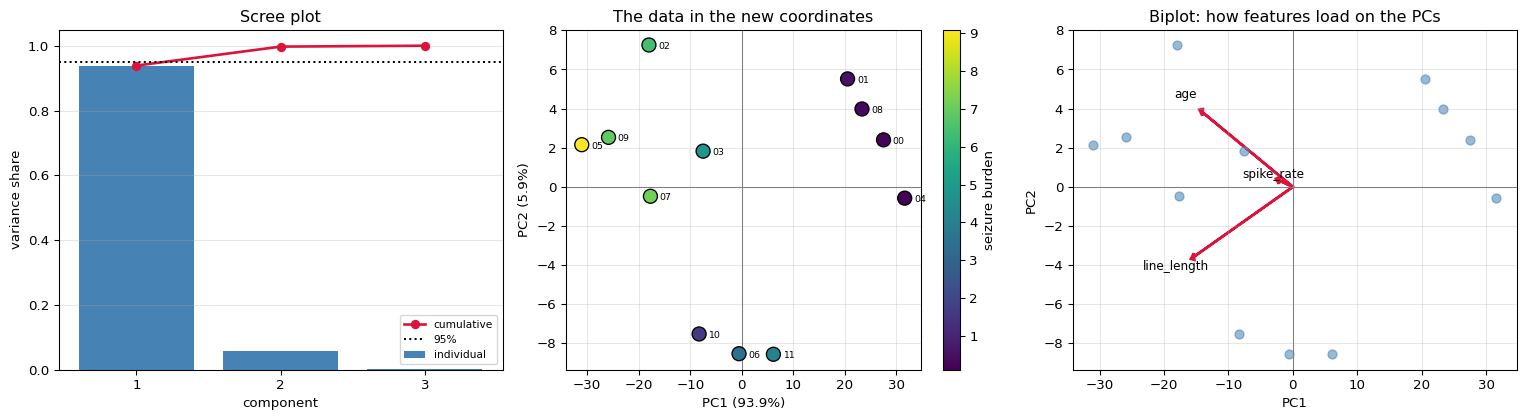

loadings - how much each original feature contributes to each component

     feature         PC1         PC2         PC3
------------------------------------------------
 line_length    -0.73182    -0.68043     0.03802
  spike_rate    -0.12226     0.07621    -0.98957
         age    -0.67044     0.72884     0.13896
------------------------------------------------

All three features load on PC1 with the same sign - PC1 is essentially
'overall severity'. PC2 contrasts them against each other.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(range(1, n_features+1), eigval/eigval.sum(), color="steelblue",
            label="individual")
axes[0].plot(range(1, n_features+1), np.cumsum(eigval)/eigval.sum(), "o-",
             color="crimson", lw=2, label="cumulative")
axes[0].axhline(.95, ls=":", color="k", label="95%")
axes[0].set(xlabel="component", ylabel="variance share", ylim=(0, 1.05),
            title="Scree plot", xticks=range(1, n_features+1))
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3, axis="y")

sc = axes[1].scatter(scores[:,0], scores[:,1], c=y_reg, cmap="viridis",
                     s=110, edgecolor="k", zorder=3)
plt.colorbar(sc, ax=axes[1], label="seizure burden")
for i in range(n_samples):
    axes[1].annotate(rec_ids[i][3:], (scores[i,0], scores[i,1]), fontsize=7,
                     xytext=(7,-3), textcoords="offset points")
axes[1].axhline(0, color="grey", lw=.8); axes[1].axvline(0, color="grey", lw=.8)
axes[1].set(xlabel=f"PC1 ({eigval[0]/eigval.sum():.1%})",
            ylabel=f"PC2 ({eigval[1]/eigval.sum():.1%})",
            title="The data in the new coordinates")
axes[1].grid(alpha=.3)

sc2 = np.sqrt(eigval)
for j, f in enumerate(feature_names):
    axes[2].arrow(0, 0, eigvec[j,0]*sc2[0], eigvec[j,1]*sc2[1],
                  head_width=.35, color="crimson", lw=2, length_includes_head=True)
    axes[2].text(eigvec[j,0]*sc2[0]*1.15, eigvec[j,1]*sc2[1]*1.15, f,
                 fontsize=9, ha="center")
axes[2].scatter(scores[:,0], scores[:,1], s=45, c="steelblue", alpha=.55)
axes[2].axhline(0, color="grey", lw=.8); axes[2].axvline(0, color="grey", lw=.8)
axes[2].set(xlabel="PC1", ylabel="PC2", title="Biplot: how features load on the PCs")
axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("loadings - how much each original feature contributes to each component\n")
print(f"{'feature':>12}  " + "  ".join(f"{'PC'+str(k+1):>10}" for k in range(n_features)))
print("-" * 48)
for j, f in enumerate(feature_names):
    print(f"{f:>12}  " + "  ".join(f"{eigvec[j,k]:>10.5f}" for k in range(n_features)))
print("-" * 48)
print("\nAll three features load on PC1 with the same sign - PC1 is essentially")
print("'overall severity'. PC2 contrasts them against each other.")

---
# 6. The SVD Route

In practice PCA is computed by singular value decomposition of the centred data, never by
forming the covariance matrix:

$$X_c = U S V^\top
\qquad\Longrightarrow\qquad
\Sigma = \frac{X_c^\top X_c}{n-1} = V\frac{S^2}{n-1}V^\top$$

So $V$ holds the same eigenvectors and $\lambda_j = s_j^2/(n-1)$.

The reason to prefer it is numerical: forming $X_c^\top X_c$ **squares the condition
number**, so precision that survives in $X_c$ can be destroyed in $\Sigma$. SVD works on
$X_c$ directly.

In [11]:
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
lam_svd = S**2 / (n_samples - 1)

print(f"singular values      : {np.round(S, 6)}")
print(f"s^2 / (n-1)          : {np.round(lam_svd, 8)}")
print(f"eigenvalues of Sigma : {np.round(eigval, 8)}")
print(f"MATCH: {np.allclose(lam_svd, eigval)}\n")

# eigenvector signs are arbitrary; align before comparing
Vt_al = Vt.copy()
for k in range(n_features):
    if np.dot(Vt_al[k], eigvec[:, k]) < 0:
        Vt_al[k] *= -1
print("components from SVD vs from eigendecomposition (signs aligned)\n")
for k in range(n_features):
    print(f"   PC{k+1}: svd {np.round(Vt_al[k], 6)}   eig {np.round(eigvec[:,k], 6)}")
print(f"\nMATCH: {np.allclose(Vt_al, eigvec.T, atol=1e-8)}")
print("\n(the sign of an eigenvector is arbitrary: if v is one, so is -v. Libraries")
print(" pick a convention, which is why signs may differ from a hand computation.)\n")

print(f"condition number of Xc    : {np.linalg.cond(Xc):>12,.2f}")
print(f"condition number of Sigma : {np.linalg.cond(Sig):>12,.2f}")
print(f"ratio                     : {np.linalg.cond(Sig)/np.linalg.cond(Xc):>12,.2f}x")
print("\nThat squaring is the whole argument for SVD.")

singular values      : [71.8027 17.942   3.8663]
s^2 / (n-1)          : [468.6937  29.2649   1.3589]
eigenvalues of Sigma : [468.6937  29.2649   1.3589]
MATCH: True

components from SVD vs from eigendecomposition (signs aligned)

   PC1: svd [-0.7318 -0.1223 -0.6704]   eig [-0.7318 -0.1223 -0.6704]
   PC2: svd [-0.6804  0.0762  0.7288]   eig [-0.6804  0.0762  0.7288]
   PC3: svd [ 0.038  -0.9896  0.139 ]   eig [ 0.038  -0.9896  0.139 ]

MATCH: True

(the sign of an eigenvector is arbitrary: if v is one, so is -v. Libraries
 pick a convention, which is why signs may differ from a hand computation.)

condition number of Xc    :        18.57
condition number of Sigma :       344.90
ratio                     :        18.57x

That squaring is the whole argument for SVD.


---
# 7. Scaled vs Unscaled

The choice made in section 2 changes the answer completely.

In [12]:
Sig_z = Xz.T @ Xz / (n_samples - 1)
ev_z, evec_z = np.linalg.eigh(Sig_z)
o = np.argsort(ev_z)[::-1]
ev_z, evec_z = ev_z[o], evec_z[:, o]

print(f"{'':>14}  {'UNSCALED':>28}  |  {'STANDARDISED':>28}")
print("-" * 78)
print(f"{'PC1 share':>14}  {eigval[0]/eigval.sum():>27.2%}  |  "
      f"{ev_z[0]/ev_z.sum():>27.2%}")
print(f"{'PC1 loadings':>14}  {str(np.round(eigvec[:,0],3)):>28}  |  "
      f"{str(np.round(evec_z[:,0],3)):>28}")
print("-" * 78)

print(f"\nPC1 loadings side by side:\n")
print(f"{'feature':>12}  {'unscaled':>10}  {'standardised':>14}")
print("-" * 42)
for j, f in enumerate(feature_names):
    print(f"{f:>12}  {eigvec[j,0]:>10.4f}  {evec_z[j,0]:>14.4f}")
print("-" * 42)
dom = feature_names[int(np.argmax(np.abs(eigvec[:,0])))]
print(f"\nUnscaled, PC1 is dominated by '{dom}' - the feature with the biggest")
print(f"numbers, not necessarily the most informative one.")
print(f"Standardised, all three contribute comparably.")
print(f"\nNeither is 'correct'. Standardise when the units are not comparable,")
print(f"which is the usual case and the safer default.")

                                    UNSCALED  |                  STANDARDISED
------------------------------------------------------------------------------
     PC1 share                       93.87%  |                       92.01%
  PC1 loadings        [-0.732 -0.122 -0.67 ]  |        [-0.571 -0.577 -0.584]
------------------------------------------------------------------------------

PC1 loadings side by side:

     feature    unscaled    standardised
------------------------------------------
 line_length     -0.7318         -0.5711
  spike_rate     -0.1223         -0.5773
         age     -0.6704         -0.5836
------------------------------------------

Unscaled, PC1 is dominated by 'line_length' - the feature with the biggest
numbers, not necessarily the most informative one.
Standardised, all three contribute comparably.

Neither is 'correct'. Standardise when the units are not comparable,
which is the usual case and the safer default.


---
# 8. Checking Against scikit-learn

In [13]:
from sklearn.decomposition import PCA

p = PCA(n_components=n_features).fit(X)

print(f"explained variance ours    : {np.round(eigval, 8)}")
print(f"explained variance sklearn : {np.round(p.explained_variance_, 8)}")
print(f"MATCH: {np.allclose(eigval, p.explained_variance_)}\n")

print(f"variance ratio ours    : {np.round(eigval/eigval.sum(), 8)}")
print(f"variance ratio sklearn : {np.round(p.explained_variance_ratio_, 8)}")
print(f"MATCH: {np.allclose(eigval/eigval.sum(), p.explained_variance_ratio_)}\n")

comp = p.components_.copy()
for k in range(n_features):
    if np.dot(comp[k], eigvec[:, k]) < 0:
        comp[k] *= -1
print(f"components MATCH (after sign alignment): "
      f"{np.allclose(comp, eigvec.T, atol=1e-8)}")

sk_scores = p.transform(X)
for k in range(n_features):
    if np.dot(sk_scores[:, k], scores[:, k]) < 0:
        sk_scores[:, k] *= -1
print(f"scores MATCH (after sign alignment)    : "
      f"{np.allclose(sk_scores, scores, atol=1e-8)}")

p1 = PCA(n_components=1).fit(X)
rec_sk = p1.inverse_transform(p1.transform(X))
print(f"\n1-component reconstruction MATCH: {np.allclose(rec_sk, recon)}")
print(f"mean of the data recovered      : {np.allclose(p.mean_, mu)}")

explained variance ours    : [468.6937  29.2649   1.3589]
explained variance sklearn : [468.6937  29.2649   1.3589]
MATCH: True

variance ratio ours    : [0.9387 0.0586 0.0027]
variance ratio sklearn : [0.9387 0.0586 0.0027]
MATCH: True

components MATCH (after sign alignment): True
scores MATCH (after sign alignment)    : True

1-component reconstruction MATCH: True
mean of the data recovered      : True


---
# 9. Summary

| Stage | Formula |
|---|---|
| Centre | $X_c = X - \boldsymbol{\mu}$ |
| Covariance | $\Sigma = \frac{1}{n-1}X_c^\top X_c$ |
| Decompose | $\Sigma\mathbf{v}_j = \lambda_j\mathbf{v}_j$ |
| Variance on PC$_j$ | $\lambda_j$ |
| Explained ratio | $\lambda_j / \sum_k \lambda_k$ |
| Project | $Z = X_c V_k$ |
| Reconstruct | $\hat{X} = ZV_k^\top + \boldsymbol{\mu}$ |
| Error | $\sum_{j>k}\lambda_j$ &mdash; the discarded variance |
| In practice | SVD of $X_c$; $\lambda_j = s_j^2/(n-1)$ |

**The one idea:** rotate the coordinate system so the axes line up with the directions of
greatest variance. Nothing is lost until you decide to drop an axis, and what you lose
when you do is exactly that axis's eigenvalue.

**Two things it is not:** PCA is **unsupervised**, so the direction of greatest variance
need not be the direction that predicts your target &mdash; a low-variance component can be
the informative one. And it is **linear**: data curved through its space (a spiral, a
manifold) will not be untangled by a rotation.

**What is deliberately left out:** kernel PCA, probabilistic PCA and factor analysis,
incremental/randomised PCA for large matrices, ICA, and the non-linear methods (t-SNE,
UMAP, autoencoders) that handle curved structure.